# Лінійна регресія

## А. Генерування фіч (регресорів, x)

Згенеруйте вибірку регресорів об'єму n=100 відповідно до варіанту

1. N(0, 1)
2. U[-5, 5]
3. Gamma(3, 3)
4. Exp(0.2)

## Б. Генерація похибок $\varepsilon_i$

Згенеруйте n=100 похибок відповідно до варіантів

1. N(0, 0.2)
2. U[-0.25, 0.2]
4. Exp(0.2)

## В. Побудуйте таргети (відгуки, у) за наступною моделлю регресії

$$y_i = \theta_0 + x_i \theta_1 + \varepsilon_i$$
де $\theta=(0.5, -0.5)$, $1\leq i\leq n$

## Г. Exploratory data analysis
- зобразіть окремо гістограми $x$ та $y$
- Зобразіть діаграму розсіювання пар $x, y$
- Чи має місце лінійна залежність
- Порахуйте кореляцію спірмена (коефіцієнт лінійної кореляції)


## Д. Оцінка параметрів моделі за МНК
- оцініть параметри моделі за МНК, порахуйте значення функціоналу МНК
- Зробіть передбачення
- Зобразіть передбачення разом із таргетами
- Зобразіть гістограму залишків (передбачення - таргети)
- Яким є середнє відхилення?
- Порахуйте лінійну кореляцію між залишками та передбаченнями. Чи вони незалежні?
- Чи вдалося гарно оцінити параметри $\theta$.  Якщо не вийшло, то яка в цьому причина?

---
# Розв'язання

**Варіант:** регресори $x\sim U[-5,5]$, похибки $\varepsilon\sim \mathrm{Exp}(0.2)$.

**Домовленості про параметризацію** :

- $\mathrm{Exp}(\lambda)$ — $\lambda$ це **інтенсивність** (rate), середнє $=1/\lambda$, тому в `numpy` `scale = 1/λ = 5`;
- $U[a,b]$ — рівномірний розподіл на відрізку.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
n = 100
theta_true = np.array([0.5, -0.5])        # (theta_0, theta_1)
rng = np.random.default_rng(SEED)

x_name = "U[-5, 5]"
e_name = "Exp(0.2)"
e_mean = 1 / 0.2                           # E(eps) = 1/lambda = 5
print(f"Регресори: {x_name};  похибки: {e_name}  (E eps = {e_mean})")

Регресори: U[-5, 5];  похибки: Exp(0.2)  (E eps = 5.0)


## А. Генерування регресорів $x$

Беремо вибірку об'єму $n=100$ із розподілу, що відповідає варіанту.

In [2]:
x = rng.uniform(-5, 5, n)
print("перші 5 значень x:", np.round(x[:5], 3))
print(f"середнє = {x.mean():.3f},  вибіркове ст. відхилення = {x.std(ddof=1):.3f}")

перші 5 значень x: [ 2.74  -0.611  3.586  1.974 -4.058]
середнє = -0.133,  вибіркове ст. відхилення = 2.736


## Б. Генерація похибок $\varepsilon_i$

In [3]:
eps = rng.exponential(scale=1/0.2, size=n)   # rate = 0.2
print("перші 5 значень eps:", np.round(eps[:5], 3))
print(f"середнє = {eps.mean():.3f} (теоретичне {e_mean}),  ст. відхилення = {eps.std(ddof=1):.3f}")

перші 5 значень eps: [ 5.044 15.412 10.232  5.589  9.253]
середнє = 5.146 (теоретичне 5.0),  ст. відхилення = 4.689


## В. Таргети $y_i=\theta_0+x_i\theta_1+\varepsilon_i$, $\ \theta=(0.5,-0.5)$

In [4]:
y = theta_true[0] + theta_true[1] * x + eps
print("перші 5 значень y:", np.round(y[:5], 3))

перші 5 значень y: [ 4.174 16.218  8.939  5.103 11.782]


## Г. Exploratory data analysis
### Гістограми $x$ та $y$

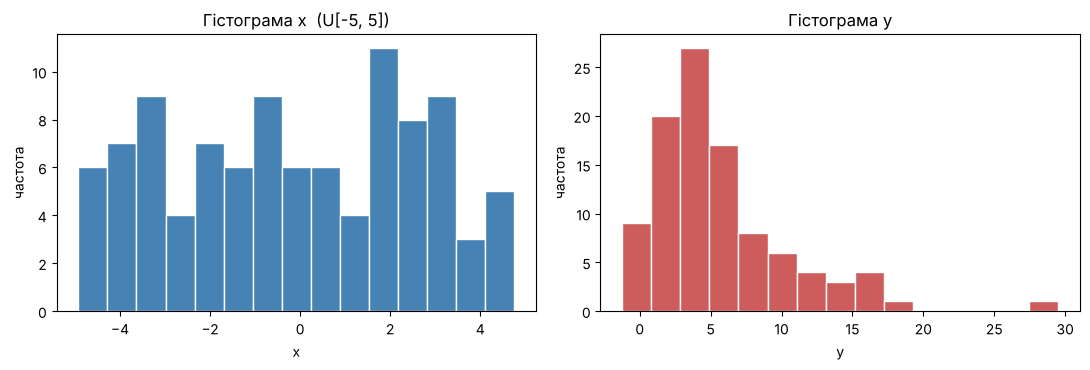

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(x, bins=15, color="steelblue", edgecolor="white")
ax[0].set_title(f"Гістограма x  ({x_name})"); ax[0].set_xlabel("x"); ax[0].set_ylabel("частота")
ax[1].hist(y, bins=15, color="indianred", edgecolor="white")
ax[1].set_title("Гістограма y"); ax[1].set_xlabel("y"); ax[1].set_ylabel("частота")
plt.tight_layout(); plt.show()

### Діаграма розсіювання та кореляції

У завданні сказано «кореляція Спірмена (коефіцієнт лінійної кореляції)». Це два різні коефіцієнти:
**Пірсона** $r$ міряє саме *лінійну* залежність, а **Спірмена** $\rho$ — це кореляція Пірсона між *рангами* (підручник, п. 5.4), вона міряє монотонну залежність. Порахуємо обидва.

Пірсон  r   = -0.2724  (p-value = 6.11e-03)
Спірмен rho = -0.2696  (p-value = 6.67e-03)
Пірсон між рангами = -0.2696  (збігається зі Спірменом)

Висновок: |r| = 0.27 — слабка лінійна залежність, знак від’ємний (узгоджено зі знаком theta_1 = -0.5).


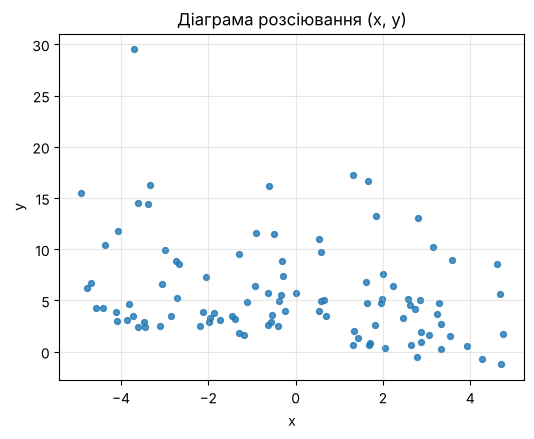

In [6]:
plt.figure(figsize=(6, 4.5))
plt.scatter(x, y, s=18, alpha=0.8)
plt.xlabel("x"); plt.ylabel("y"); plt.title("Діаграма розсіювання (x, y)")
plt.grid(alpha=0.3); plt.show()

r_p, p_p = stats.pearsonr(x, y)
rho_s, p_s = stats.spearmanr(x, y)
print(f"Пірсон  r   = {r_p:.4f}  (p-value = {p_p:.2e})")
print(f"Спірмен rho = {rho_s:.4f}  (p-value = {p_s:.2e})")

# Перевірка: Спірмен = Пірсон між рангами (формула 5.1 у підручнику)
rho_check = np.corrcoef(stats.rankdata(x), stats.rankdata(y))[0, 1]
print(f"Пірсон між рангами = {rho_check:.4f}  (збігається зі Спірменом)")

strength = "сильна" if abs(r_p) > 0.7 else "помірна" if abs(r_p) > 0.4 else "слабка"
print(f"\nВисновок: |r| = {abs(r_p):.2f} — {strength} лінійна залежність, "
      f"знак {'від’ємний' if r_p < 0 else 'додатний'}"
      f" (узгоджено зі знаком theta_1 = {theta_true[1]}).")

## Д. Оцінка параметрів за МНК

Функціонал МНК:
$$Q(\theta)=\sum_{i=1}^n\bigl(y_i-\theta_0-\theta_1x_i\bigr)^2\to\min.$$
Розв'язок для простої лінійної регресії:
$$\hat\theta_1=\frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sum(x_i-\bar x)^2},\qquad \hat\theta_0=\bar y-\hat\theta_1\bar x .$$
Те саме в матричному вигляді: $\hat\theta=(X^TX)^{-1}X^Ty$, де $X=[\mathbf 1,\;x]$.

In [7]:
# 1) Явні формули
th1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean())**2)
th0 = y.mean() - th1 * x.mean()
theta_hat = np.array([th0, th1])

# 2) Перевірка матричним способом (нормальні рівняння) та lstsq
X = np.column_stack([np.ones(n), x])
theta_ne = np.linalg.solve(X.T @ X, X.T @ y)
theta_ls = np.linalg.lstsq(X, y, rcond=None)[0]
assert np.allclose(theta_hat, theta_ne) and np.allclose(theta_hat, theta_ls)

def Q(theta):
    return np.sum((y - theta[0] - theta[1] * x) ** 2)

print(f"theta_hat = ({th0:.4f}, {th1:.4f})")
print(f"theta_true = ({theta_true[0]}, {theta_true[1]})")
print(f"Q(theta_hat)  = {Q(theta_hat):.4f}   <- мінімум функціоналу МНК")
print(f"Q(theta_true) = {Q(theta_true):.4f}   (при справжніх параметрах Q не менший)")

theta_hat = (5.6479, -0.4851)
theta_true = (0.5, -0.5)
Q(theta_hat)  = 2176.1181   <- мінімум функціоналу МНК
Q(theta_true) = 4824.3213   (при справжніх параметрах Q не менший)


### Передбачення разом із таргетами

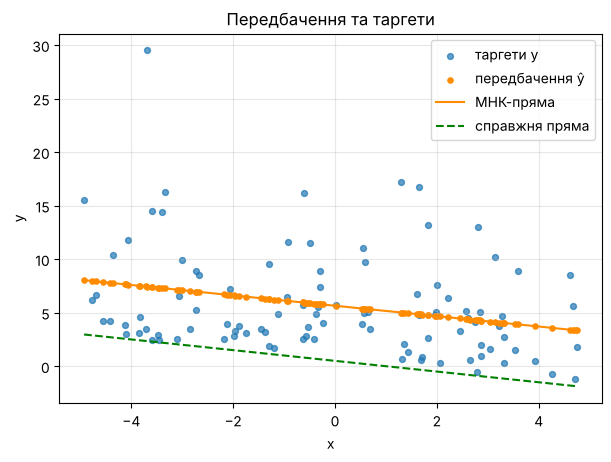

In [8]:
y_pred = X @ theta_hat

xs = np.linspace(x.min(), x.max(), 200)
plt.figure(figsize=(7, 4.8))
plt.scatter(x, y, s=18, alpha=0.7, label="таргети y")
plt.scatter(x, y_pred, s=14, color="darkorange", label="передбачення ŷ")
plt.plot(xs, th0 + th1 * xs, color="darkorange", lw=1.5, label="МНК-пряма")
plt.plot(xs, theta_true[0] + theta_true[1] * xs, "g--", lw=1.5, label="справжня пряма")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Передбачення та таргети"); plt.show()

### Залишки (передбачення − таргети)

Середнє відхилення (середнє залишків) = 2.22e-15
Середнє абсолютне відхилення          = 3.5054
Ст. відхилення залишків (ddof=1)      = 4.6884
Середньоквадратична похибка (RMSE)    = 4.6649


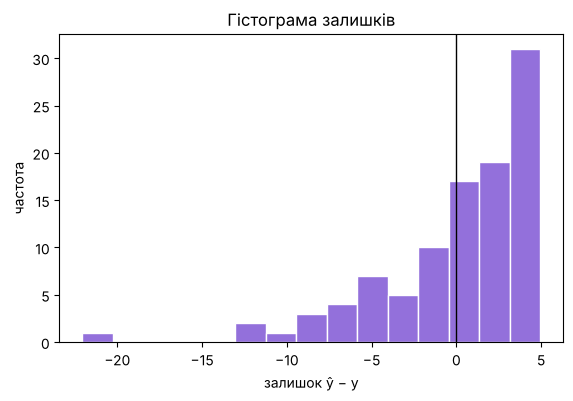

In [9]:
resid = y_pred - y          # як у завданні: передбачення мінус таргети

plt.figure(figsize=(6.5, 4))
plt.hist(resid, bins=15, color="mediumpurple", edgecolor="white")
plt.axvline(0, color="k", lw=1)
plt.xlabel("залишок ŷ − y"); plt.ylabel("частота"); plt.title("Гістограма залишків"); plt.show()

print(f"Середнє відхилення (середнє залишків) = {resid.mean():.2e}")
print(f"Середнє абсолютне відхилення          = {np.mean(np.abs(resid)):.4f}")
print(f"Ст. відхилення залишків (ddof=1)      = {resid.std(ddof=1):.4f}")
print(f"Середньоквадратична похибка (RMSE)    = {np.sqrt(np.mean(resid**2)):.4f}")

corr(залишки, передбачення): Пірсон = 5.62e-17, Спірмен = 0.1025


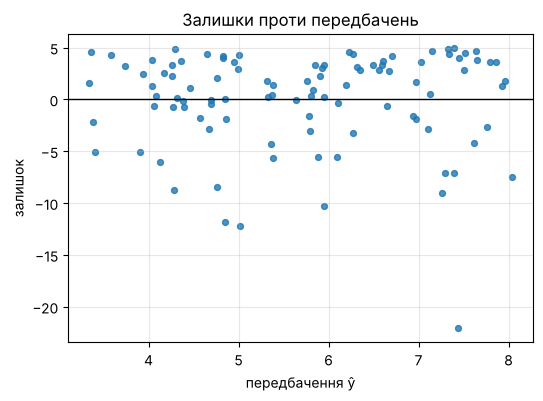

In [10]:
r_rp, p_rp = stats.pearsonr(resid, y_pred)
rho_rp, _  = stats.spearmanr(resid, y_pred)
print(f"corr(залишки, передбачення): Пірсон = {r_rp:.2e}, Спірмен = {rho_rp:.4f}")

plt.figure(figsize=(6, 4))
plt.scatter(y_pred, resid, s=18, alpha=0.8)
plt.axhline(0, color="k", lw=1)
plt.xlabel("передбачення ŷ"); plt.ylabel("залишок"); plt.title("Залишки проти передбачень")
plt.grid(alpha=0.3); plt.show()

**Чому Пірсон ≈ 0 (≈ $10^{-16}$)?** Це не випадковість, а наслідок МНК: нормальні рівняння $X^T(y-X\hat\theta)=0$ означають, що вектор залишків ортогональний до стовпців $\mathbf 1$ та $x$, а отже й до $\hat y=X\hat\theta$. Тому (1) середнє залишків $=0$ і (2) вибіркова кореляція залишків із передбаченнями рівна нулю **завжди**, за побудовою.

**Чи вони незалежні?** Некорельованість ≠ незалежність. Нульова лінійна кореляція — лише необхідна умова. Для гауссових похибок $\hat\varepsilon$ і $\hat y$ спільно гауссові, тож некорельовані ⇒ незалежні. Для негауссових похибок (рівномірні, експоненційні) строгої незалежності гарантувати не можна — її можна лише перевіряти графічно (діаграма «залишки проти передбачень» без структури, постійний розкид) та непараметричними тестами (рангова кореляція Спірмена, див. вище).

### Чи вдалося оцінити $\theta$?

Порівняємо оцінки зі справжніми значеннями за допомогою довірчих інтервалів. Для $\hat\theta$ оцінка дисперсії похибки $s^2=Q(\hat\theta)/(n-2)$, а $\mathrm{Var}(\hat\theta)=s^2(X^TX)^{-1}$.

In [11]:
s2 = Q(theta_hat) / (n - 2)
cov_theta = s2 * np.linalg.inv(X.T @ X)
se = np.sqrt(np.diag(cov_theta))
tcrit = stats.t.ppf(0.975, df=n - 2)
ci = np.column_stack([theta_hat - tcrit * se, theta_hat + tcrit * se])

print(f"{'':8s}{'істинне':>9s}{'оцінка':>9s}{'ст.пох.':>9s}   95% довірчий інтервал   містить істинне?")
for k, name in enumerate(["theta_0", "theta_1"]):
    ok = ci[k, 0] <= theta_true[k] <= ci[k, 1]
    print(f"{name:8s}{theta_true[k]:9.3f}{theta_hat[k]:9.3f}{se[k]:9.3f}   [{ci[k,0]:7.3f}, {ci[k,1]:7.3f}]     {'так' if ok else 'НІ'}")

print(f"\nR^2 = {1 - Q(theta_hat) / np.sum((y - y.mean())**2):.3f}")
print(f"Теоретичне E(eps) = {e_mean}.  Очікуваний зсув theta_0: {e_mean:+.3f}  "
      f"(МНК із вільним членом оцінює theta_0 + E(eps) = {theta_true[0] + e_mean:.3f})")
if abs(e_mean) > 0.1:
    print("Висновок: E(eps) != 0, порушена умова моделі -> оцінка theta_0 зміщена на E(eps); "
          "theta_1 при цьому оцінюється добре.")
elif all(ci[k, 0] <= theta_true[k] <= ci[k, 1] for k in range(2)):
    print("Висновок: параметри оцінено добре, справжні значення в довірчих інтервалах.")
else:
    print("Висновок: збіг у межах похибки, але інтервал не накрив істинне значення (можливий випадковий збіг).")

          істинне   оцінка  ст.пох.   95% довірчий інтервал   містить істинне?
theta_0     0.500    5.648    0.472   [  4.712,   6.584]     НІ
theta_1    -0.500   -0.485    0.173   [ -0.829,  -0.142]     так

R^2 = 0.074
Теоретичне E(eps) = 5.0.  Очікуваний зсув theta_0: +5.000  (МНК із вільним членом оцінює theta_0 + E(eps) = 5.500)
Висновок: E(eps) != 0, порушена умова моделі -> оцінка theta_0 зміщена на E(eps); theta_1 при цьому оцінюється добре.


## Висновки

1. **Лінійна залежність** є, але слабка: $x\sim U[-5,5]$ має велику дисперсію ($\approx 8.3$), проте шум $\mathrm{Exp}(0.2)$ має дисперсію $1/0.2^2=25$, що значно більше за сигнал $\theta_1^2\mathrm{Var}(x)\approx 2.1$. Тому $r\approx\rho\approx-0.27$: знак від'ємний (як у $\theta_1$), але точки сильно розкидані навколо прямої.
2. **Спірмен і Пірсон** майже збігаються, бо залежність монотонна й приблизно лінійна.
3. **Оцінки МНК.** $\hat\theta_1\approx-0.49$ добре збігається з $-0.5$ (і потрапляє у довірчий інтервал), а $\hat\theta_0\approx5.6$ — **зовсім не $0.5$**.
4. **Причина.** Похибки $\mathrm{Exp}(0.2)$ мають $E\varepsilon=5\neq0$, тобто порушена стандартна умова моделі $E\varepsilon_i=0$. Константа $5$ «зливається» з вільним членом, і МНК фактично оцінює $\theta_0+E\varepsilon=0.5+5=5.5$. Нахил $\theta_1$ при цьому не страждає, бо константа на нього не впливає. Виправити можна, якщо працювати з центрованими похибками $\varepsilon-E\varepsilon$ (тоді $\hat\theta_0-5\approx0.5$).
5. **Залишки.** Середнє залишків і кореляція залишків із передбаченнями дорівнюють нулю за побудовою МНК (ортогональність), тому це не перевірка якості. Гістограма залишків має асиметричну форму експоненційного розподілу (без нормальності), тому з нульової кореляції не випливає незалежність.